In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import yaml
import seaborn as sns
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats
import torch
from scipy import stats
from tqdm import tqdm
import velotest
from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors_in_direction_of_velocity, find_neighbors

from matplotlib.ticker import ScalarFormatter, NullLocator
from matplotlib.colors import LogNorm 

In [2]:
def calculateBound(adata, k=None, neighbors=True, number_neighbors=200): 
    if neighbors is True:
        nn_indices_optimal = find_neighbors(torch.tensor(adata.layers['Ms']), k_neighbors=number_neighbors)

    mins = torch.tensor([-2.]*len(adata))
    maxs = torch.tensor([-2.]*len(adata))
    for i in tqdm(range(len(adata))):
        cos = torch.nn.CosineSimilarity(dim=1, eps=1e-6)
        if neighbors is True:
            expression_all = torch.tensor(adata.layers['Ms'][nn_indices_optimal[i]][:,adata.var.velocity_genes])
        else:
            expression_all = torch.tensor(adata.layers['Ms'][:,adata.var.velocity_genes])
        expression_cell = torch.tensor(adata.layers['Ms'][i,adata.var.velocity_genes]).unsqueeze(0)
        velocity = torch.tensor(adata.layers['velocity'][i,adata.var.velocity_genes]).unsqueeze(0)
        cosines = cos(expression_all - expression_cell, velocity)
        cosines = torch.cat([cosines[:i], cosines[i+1:]])
        if k is None:
            mins[i] = torch.min(cosines)
            maxs[i] = torch.max(cosines)
        else:
            mins[i] = torch.mean(torch.topk(cosines, largest=False, k=k).values)
            maxs[i] = torch.mean(torch.topk(cosines, largest=True, k=k).values)

    return maxs

def bestVelocityEmbedded(adata, basis, num=200):
    # Run test - tsne
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, 
                                                                           basis=basis, 
                                                                           number_neighbors_to_sample_from=num, 
                                                                           null_distribution="velocities-explicit", 
                                                                           cosine_empty_neighborhood=None, 
                                                                           correction="bonferroni", 
                                                                           restrict_to_velocity_genes=True, 
                                                                           exclusion_degree=10)
    statistics = debug_dict['statistics']

    # Calculate emmbeding test optimal statistic
    best_value = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]

    return best_value

In [3]:
datasets = {
        "Pancreas_dynamical": "../configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "../configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "../configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "../configs/gastrulation.yaml",
        "Bone_marrow": "../configs/bonemarrow.yaml",
        "PBMC": "../configs/pbmc.yaml",
        "Covid": "../configs/covid.yaml",
        "Retinal_development": "../configs/retinal_development.yaml",
        "Human_HSC": "../configs/humanHSC.yaml",
        "Intestinal_development": "../configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "../configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "../configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "../configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "../configs/noEmbedding/human_cerebral.yaml",
        "Hematopoiesis_mouse": "../configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "../configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "../configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "../configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"../configs/noEmbedding/GSE128365.yaml"
    }

x = {}
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    x[name] = adata.n_obs  


In [ ]:
results = {}

for name, path in datasets.items():
    # Open and collect data information
    with open(path, "r") as f:
        config = yaml.safe_load(f)
    adata = sc.read(config["path"])
    
    neighbors = [2000] # Run this multiple times with different neighbors to see how it changes (merge and concatenate the files after)
    distances = {}
    # Upper bound with differnt neighbors
    for i, num in enumerate(neighbors):
        if (num+1000) >= adata.n_obs:
            print("Jump", name)
            continue
        print("noJump", name)
        upper_bound = calculateBound(adata, neighbors=True, number_neighbors=num)
    
        # Test optimal with original embedding
        bound = bestVelocityEmbedded(adata, config['basis'], num)

        distances[f"n_{num}"] = stats.wasserstein_distance(upper_bound, bound)

    results[name] = distances

df = pd.DataFrame(results)
df.to_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_2000.csv")

noJump Pancreas_dynamical


100%|██████████| 3696/3696 [04:14<00:00, 14.50it/s]


Dropping all the genes which are not velocity genes. 1027 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [09:54<00:00,  6.22it/s]


noJump Pancreas_stochastic


...

Dropping all the genes which are not velocity genes. 386 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 5422/5422 [12:02<00:00,  7.50it/s]


noJump Hindbrain_mouse


  8%|▊         | 1085/13501 [01:06<12:37, 16.39it/s]


KeyboardInterrupt: 

In [5]:
df = pd.DataFrame(results)
df.to_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_2000.csv")

In [6]:
# Load measuremnts for all datasets
df1 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes.csv", index_col=0)
df2 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_all.csv", index_col=0)
dfo = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_oligo.csv", index_col=0)
df2o = df2.merge(dfo, left_index=True, right_index=True)
df2000_1 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_2000.csv", index_col=0)
df2000_2 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_2000_2.csv", index_col=0)
df2000 = df2000_1.merge(df2000_2, left_index=True, right_index=True)
df_complete = pd.concat([df1, df2o, df2000])
df_complete

,Pancreas_dynamical,Pancreas_stochastic,Dentate_gyrus,Gastrulation_erythroid,Bone_marrow,PBMC,Covid,Retinal_development,Human_HSC,Intestinal_development,Hindbrain_mouse,Oligodendrocyte_mouse,Bone_marrow_mouse,Cerebral_cortex_human,Hematopoiesis_mouse,Spermatogenisis,Old_brain,Prefrontal_cortex,Intestinal_organoids
n_10,0.041831,0.020482,0.019517,0.024818,0.126962,0.110775,0.042780,0.044301,0.046791,0.025152,0.055675,0.271457,0.020701,0.009829,0.010144,0.005741,0.052688,0.114195,0.019447
n_25,0.095621,0.039616,0.043918,0.065094,0.124151,0.250847,0.086137,0.105332,0.127272,0.078648,0.128281,0.193147,0.041800,0.043250,0.028473,0.021213,0.044531,0.128923,0.053941
n_50,0.148577,0.057403,0.067845,0.116808,0.184349,0.413394,0.126181,0.152687,0.229513,0.132163,0.212808,0.211932,0.100280,0.089687,0.043798,0.036109,0.093909,0.182206,0.106057
n_100,0.174910,0.065121,0.084481,0.161218,0.262546,0.569294,0.166786,0.177302,0.308744,0.192682,0.307140,0.289780,0.120787,0.126547,0.056546,0.091770,0.140575,0.206610,0.128687
n_200,0.179060,0.064260,0.092049,0.187529,0.307144,0.670491,0.195718,0.191313,0.350637,0.219767,0.365995,0.365328,0.151496,0.154265,0.069195,0.090982,0.154069,0.214268,0.165548
n_300,0.176633,0.063598,0.094787,0.198846,0.316442,0.711169,0.206046,0.193843,0.362515,0.229726,0.385195,0.402018,0.157257,0.166552,0.074252,0.082851,0.163072,NaN,0.183693
n_400,0.177339,0.063243,0.096190,0.204559,0.322152,0.733797,0.214965,0.195030,0.367269,0.234849,0.392593,0.424209,0.156585,0.175485,0.079929,0.078248,0.183972,NaN,0.194448
n_800,0.164928,0.065809,0.101574,0.215601,0.319672,0.770851,0.225391,0.161630,0.369515,0.239383,0.402475,0.467111,0.131818,0.196489,NaN,0.079867,0.245494,NaN,0.211138
n_1200,0.150711,0.067471,0.105473,0.218546,0.323341,0.782105,0.226804,0.158065,0.366704,0.238303,0.403995,0.482082,0.133913,0.206506,NaN,NaN,NaN,NaN,0.219487
n_1600,0.161580,0.067200,0.112908,0.218393,0.320709,0.786639,0.229753,0.163663,0.364361,0.238726,0.404825,0.490552,NaN,0.211337,NaN,NaN,NaN,NaN,0.224769


In [ ]:
# Save the one full table
df_complete.to_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_complete.csv")

      index               Dataset  Measurement  CellCount  Neighbors  \
0      n_10    Pancreas_dynamical     0.041831       3696         10   
1      n_25    Pancreas_dynamical     0.095621       3696         25   
2      n_50    Pancreas_dynamical     0.148577       3696         50   
3     n_100    Pancreas_dynamical     0.174910       3696        100   
4     n_200    Pancreas_dynamical     0.179060       3696        200   
..      ...                   ...          ...        ...        ...   
204   n_400  Intestinal_organoids     0.194448       3831        400   
205   n_800  Intestinal_organoids     0.211138       3831        800   
206  n_1200  Intestinal_organoids     0.219487       3831       1200   
207  n_1600  Intestinal_organoids     0.224769       3831       1600   
208  n_2000  Intestinal_organoids     0.244575       3831       2000   

     Proportion  
0      0.002706  
1      0.006764  
2      0.013528  
3      0.027056  
4      0.054113  
..          ...  
204    0.

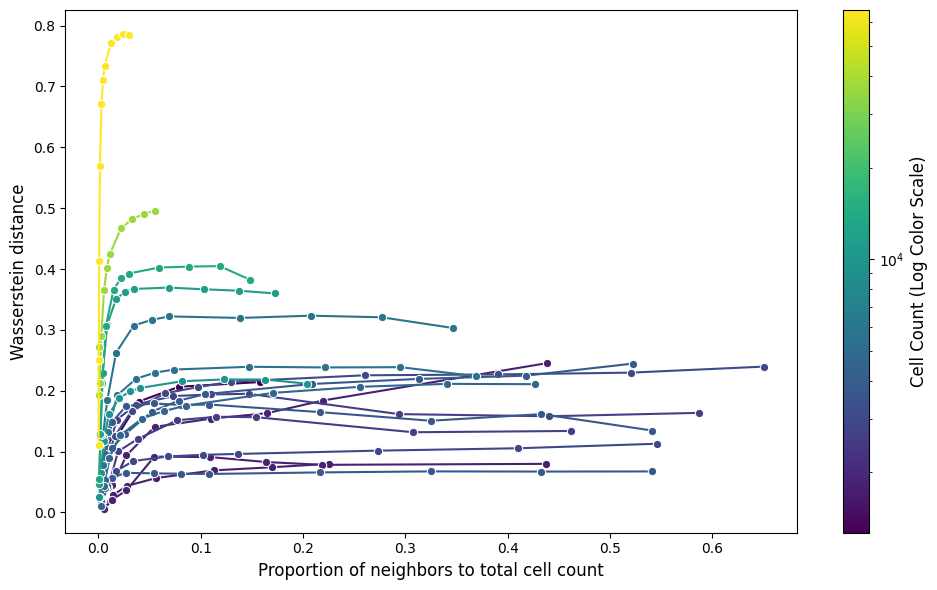

In [10]:
# Prepare dataset for plotting
df_complete = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_complete.csv", index_col=0)
count_df = pd.DataFrame(list(x.items()), columns=['Dataset', 'CellCount'])
df_long = df_complete.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')

plot_df = pd.merge(df_long, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']
print(plot_df)

# Prepare color scale 
vmin = plot_df['CellCount'].min()
vmax = plot_df['CellCount'].max()
log_norm = LogNorm(vmin=vmin, vmax=vmax)

# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_df, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount', 
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legend
if ax.get_legend() is not None:
    ax.get_legend().remove()
sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Cell Count (Log Color Scale)', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 

plt.tight_layout()
plt.show()